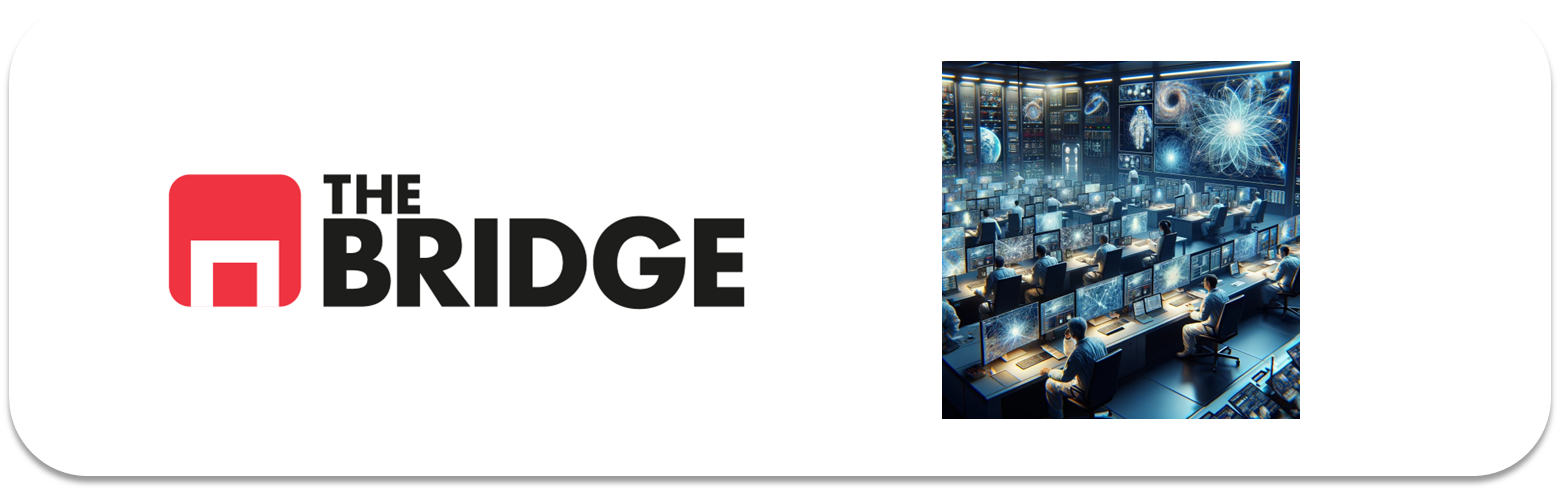

## PRÁCTICA OBLIGATORIA: **Redes Convolucionales**

* La práctica obligatoria de esta unidad consiste en un ejercicio de construcción de una red convolucional con Keras para la clasificación de imágenes de simpáticos perretes y gatetes. Puedes trabajar en local o en Colab: las imágenes se descargan desde Kaggle con `kagglehub` (no hace falta tener cuenta).
* Recuerda que debes subirla a tu repositorio personal antes de la sesión en vivo para que puntúe adecuadamente.
* Recuerda también que no es necesario que esté perfecta, sólo es necesario que se vea el esfuerzo.
* Esta práctica se resolverá en la sesión en vivo correspondiente y la solución se publicará en el repo del curso. 

<table align="left">
  <td>
    <a href="https://colab.research.google.com/github/DS-TB-FundacionUniversia/2026-09-DS-Universia/blob/main/05_Deep_Learning/02_Convolucionales_CNN/soluciones/P01_Practica_CNN_SOL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>
  </td>
</table>

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook.

In [1]:
import cv2 # opencv
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import random

from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.utils import shuffle
from skimage.io import imread

import keras
from tensorflow.keras.preprocessing.image import ImageDataGenerator # En Keras 3 sólo queda como "legacy" a través de tensorflow.keras

from time import time

pd.options.mode.copy_on_write = True # CoW por defecto a partir de pandas 3.0.0
keras.utils.set_random_seed(42) # Para que los entrenamientos sean (casi) reproducibles

### Problema de Negocio y dataset

Una conocida empresa de información inmobiliaria utiliza un CAPTCHA visual de perros y gatos para detectar webscrappings intensivos y ataques de denegación de servicio. Últimamente, ha detectado que su sistema está empezando a flojear, es decir que hay muchos sistemas de detección automática de imágenes que son capaces de detectar que es un perro y un gato y saltarse el CAPTCHA antirobots. Por eso nos ha pedido que entrenemos un modelo potente de clasificación que emule a estos sistemas con el objetivo de emplear como fotografías para el CAPTCHA aquellas que no sepa detectar este sistema emulador de chicos malos.

Pues manos a la obra, tenemos que seleccionar en un conjunto de 1000 imágenes aquellas que peor se le daría a un potencial sistema anti-CAPTCHA.

Para ello vamos a emplear el dataset [Dogs vs Cats](https://www.kaggle.com/datasets/salader/dogsvscats) de Kaggle, que ya viene separado en dos directorios `train` (20000 imágenes) y `test` (5000), cada uno con un subdirectorio por clase (`cats` y `dogs`). Para que los entrenamientos no se eternicen trabajaremos con una muestra aleatoria: 4000 imágenes de train (2000 de cada clase) y 1000 de test (500 de cada clase), que son las que tendremos que clasificar y de las que luego seleccionaremos las más "difíciles".

Para descargarlo usa `kagglehub` (ya viene instalado en Colab; en local `pip install kagglehub`):

```python
import kagglehub
PATH_DATA = kagglehub.dataset_download("salader/dogsvscats") # ~570 MB la primera vez, después queda en caché
TRAIN_PATH = os.path.join(PATH_DATA, "train")
TEST_PATH = os.path.join(PATH_DATA, "test")
```

### Se pide

1. Crear los datasets X,y de train y test, leyendo las imágenes de los directorios correspondientes (2000 imágenes por clase en train y 500 por clase en test, escogidas al azar) y a la vez que se leen adaptar su resolución para que todas tengan un tamaño de 32x32. En este caso puedes adaptar las funciones de los ejercicios de la unidad. NOTA: Ten en cuenta que la clase a la que pertenece la foto está tanto en el nombre del subdirectorio como en el del archivo (`cat.123.jpg`).

2. Crea un modelo DL basado en redes convolucionales con al menos dos juegos Convolucional-Pooling. Sigue todo el proceso de ML (visualización del dataset, MiniEDA, Construcción del modelo)

3. Entrenar el modelo con un callback de Earlystopping con paciencia la que tengas :-). Muestra su historial de entrenamiento.

4. Evalúa el modelo, haz un reporte de clasificación y muestra la matriz de confusión.

5. Es el momento de seleccionar las imágenes: Selecciona el 10% de imágenes mal clasificadas de una y otra clase que tengan el mayor nivel de confianza de que pertenecían a la clase errónea. Es decir las imágenes de perros clasificadas como gatos y con la probabilidad de ser gato más alta (y viceversa).


### Extra

Repite los pasos 3 a 5 utilizando el generador de imágenes sintéticas o Image Augmentation de Keras. 

### Resolución

### #1

#### Carga de datos

*Descargamos el dataset con `kagglehub`. Devuelve la ruta local donde lo ha dejado (una caché en tu carpeta de usuario, o en `/root/.cache` en Colab), así que no ocupa sitio en el repositorio.*

In [2]:
PATH_DATA = kagglehub.dataset_download("salader/dogsvscats")
TRAIN_PATH = os.path.join(PATH_DATA, "train")
TEST_PATH = os.path.join(PATH_DATA, "test")
for directorio in [TRAIN_PATH, TEST_PATH]:
    for clase in sorted(os.listdir(directorio)):
        print(os.path.basename(directorio), clase, len(os.listdir(os.path.join(directorio, clase))))

train cats 10000
train dogs 10000
test cats 2500
test dogs 2500


*20000 imágenes en train y 5000 en test, perfectamente equilibradas. Como nos piden, nos quedaremos con una muestra aleatoria (con semilla, para que sea reproducible) de 2000 por clase en train y 500 por clase en test. Si tienes GPU (o paciencia) puedes subir estos números.*

In [3]:
N_TRAIN_POR_CLASE = 2000
N_TEST_POR_CLASE = 500

*Adaptamos la función de lectura de los ejercicios: recorre los subdirectorios de clase, toma una muestra de ficheros, los lee y redimensiona. Además devolvemos la ruta de cada fichero (relativa a `PATH_DATA`) para poder ver después la imagen original con su resolución completa.*

In [4]:
def read_data(subdirectorio, n_por_clase = None, reshape_dim = (32,32), random_state = 42):
    rng = random.Random(random_state)
    X = []
    y = []
    rutas = []
    for clase in sorted(os.listdir(os.path.join(PATH_DATA, subdirectorio))): # cats, dogs
        ficheros = sorted(os.listdir(os.path.join(PATH_DATA, subdirectorio, clase)))
        if n_por_clase:
            ficheros = rng.sample(ficheros, n_por_clase)
        for fichero in ficheros:
            ruta = "/".join([subdirectorio, clase, fichero]) # Ruta relativa a PATH_DATA
            image = imread(os.path.join(PATH_DATA, ruta))
            image = cv2.resize(image, reshape_dim) # Redimensionamos las imágenes a 32x32
            X.append(image)
            y.append(fichero.split(".")[0]) # El nombre del fichero (cat.123.jpg) nos da la clase
            rutas.append(ruta) # Esto para ver la imagen al completo con su resolución

    return np.array(X), np.array(y), rutas

*Empezamos con el X_train, y_train*

In [5]:
X_train, y_train, train_map = read_data("train", N_TRAIN_POR_CLASE)

*Ahora el test*

In [6]:
X_test, y_test, test_map = read_data("test", N_TEST_POR_CLASE)

#### Visualización de datos

*Un pequeño vistazo al tipo y tamaño de nuestros datos*

In [7]:
X_train

array([[[[166, 166, 166],
         [168, 168, 168],
         [169, 169, 169],
         ...,
         [ 82,  25,   0],
         [ 89,  27,   2],
         [ 88,  28,   4]],

        [[166, 166, 166],
         [166, 166, 166],
         [167, 167, 167],
         ...,
         [ 83,  26,   0],
         [ 84,  22,   0],
         [ 86,  30,   5]],

        [[162, 164, 164],
         [166, 166, 166],
         [166, 166, 166],
         ...,
         [ 80,  24,   0],
         [ 77,  24,   2],
         [ 80,  24,   1]],

        ...,

        [[145, 145, 141],
         [141, 141, 139],
         [127, 128, 120],
         ...,
         [206, 224, 236],
         [140, 165, 185],
         [135, 160, 182]],

        [[140, 140, 140],
         [139, 139, 137],
         [133, 134, 126],
         ...,
         [158, 176, 188],
         [133, 159, 172],
         [128, 154, 169]],

        [[142, 137, 131],
         [114, 110,  98],
         [107,  99,  80],
         ...,
         [139, 168, 180],
        

In [8]:
X_train.ndim

4

In [9]:
X_train.shape

(4000, 32, 32, 3)

*Train: 4000 imágenes, de 32x32 y en color, 3 canales*

In [10]:
type(X_train[123])

numpy.ndarray

In [11]:
X_train.dtype

dtype('uint8')

*Y son arrays como ya sabíamos porque es lo que retorna nuestra función :-)*

In [12]:
X_test.shape

(1000, 32, 32, 3)

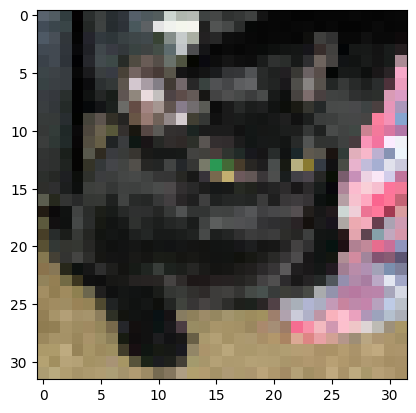

In [13]:
plt.imshow(X_test[3])

In [14]:
y_test[3]

'cat'

*Test: 1000 imágenes de 32x32, en color, 3 canales*

*Para ver nuestros datos, reutilizamos directamente la función creada para el ejercicio de los paisajes*

In [15]:
def show_images_batch(pets, names = [], n_cols = 5, size_scale = 2):
    n_rows = ((len(pets) - 1) // n_cols + 1)
    plt.figure(figsize=(n_cols * size_scale, n_rows * 1.1*size_scale))
    for index, pet in enumerate(pets):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(pet)
        plt.axis("off")
        if len(names):
            plt.title(names[index])

In [16]:
def show_images_files(rutas, names = [], n_cols = 5, size_scale = 2):
    n_rows = ((len(rutas) - 1) // n_cols + 1)
    plt.figure(figsize=(n_cols * size_scale, n_rows * 1.1*size_scale))
    for index, ruta in enumerate(rutas):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(imread(os.path.join(PATH_DATA, ruta)))
        plt.axis("off")
        if len(names):
            plt.title(names[index])

*Veamos algunas seleccionadas aleatoriamente*

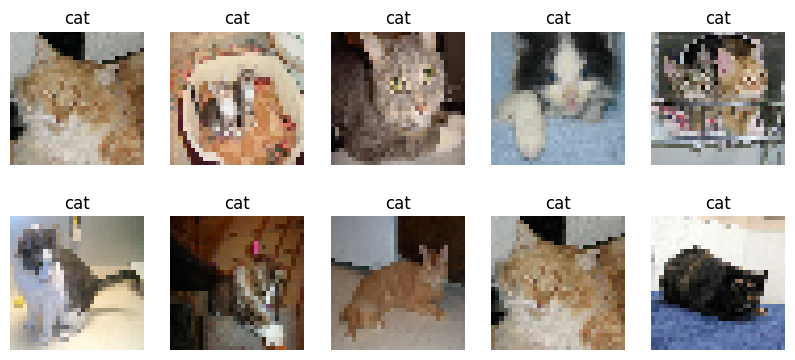

In [17]:
indices = np.random.randint(100,300,10)
show_images_batch(X_train[indices], names= y_train[indices])

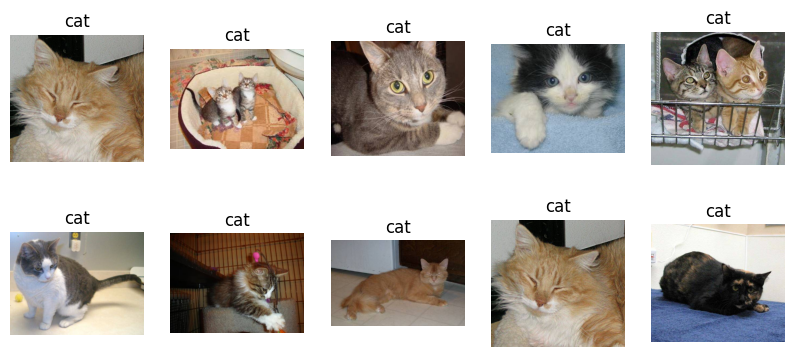

In [18]:
show_images_files([train_map[i] for i in indices], names= y_train[indices])

*Nos salen solo gatos porque están ordenados (primero 2000 gatos, luego 2000 perros), veamos algunos simpáticos perritos*

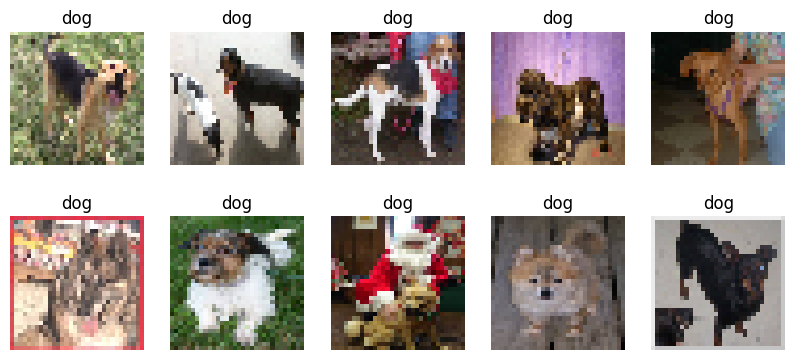

In [19]:
indices = np.random.randint(2000,2300,10)
show_images_batch(X_train[indices], names= y_train[indices])

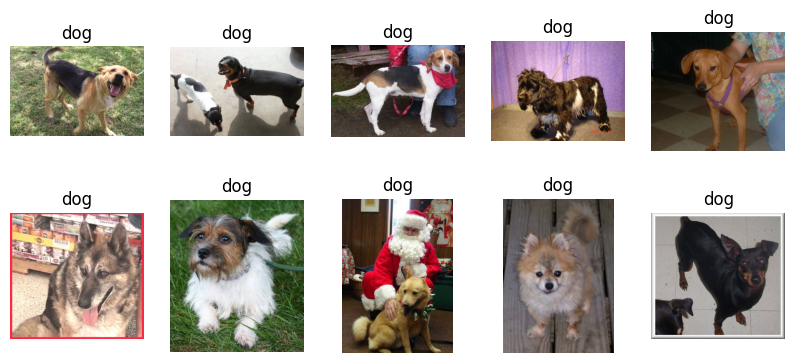

In [20]:
show_images_files([train_map[i] for i in indices], names= y_train[indices])

#### MiniEDA

*Como en todo modelo de ML, y DL es un subconjunto, vamos a analizar el target*

In [21]:
pd.Series(y_train).value_counts(True)

cat    0.5
dog    0.5
Name: proportion, dtype: float64

*Tenemos un dataset completamente equilibrado para un problema de clasificación binaria*

In [22]:
X_train.shape

(4000, 32, 32, 3)

In [23]:
X_train.dtype

dtype('uint8')

#### Escalado

*Siempre es interesante hacer un escalado aunque sea el caso de imágenes con los canales ya "escalados" entre 0 y 255. Reducir el rango de 0/255 a -1/1 o 0/1, aprovecha mejor las funciones de activación y evita problemas de saturación.*

In [24]:
X_train = X_train/255
X_test = X_test/255

In [25]:
X_train[0]

array([[[0.65098039, 0.65098039, 0.65098039],
        [0.65882353, 0.65882353, 0.65882353],
        [0.6627451 , 0.6627451 , 0.6627451 ],
        ...,
        [0.32156863, 0.09803922, 0.        ],
        [0.34901961, 0.10588235, 0.00784314],
        [0.34509804, 0.10980392, 0.01568627]],

       [[0.65098039, 0.65098039, 0.65098039],
        [0.65098039, 0.65098039, 0.65098039],
        [0.65490196, 0.65490196, 0.65490196],
        ...,
        [0.3254902 , 0.10196078, 0.        ],
        [0.32941176, 0.08627451, 0.        ],
        [0.3372549 , 0.11764706, 0.01960784]],

       [[0.63529412, 0.64313725, 0.64313725],
        [0.65098039, 0.65098039, 0.65098039],
        [0.65098039, 0.65098039, 0.65098039],
        ...,
        [0.31372549, 0.09411765, 0.        ],
        [0.30196078, 0.09411765, 0.00784314],
        [0.31372549, 0.09411765, 0.00392157]],

       ...,

       [[0.56862745, 0.56862745, 0.55294118],
        [0.55294118, 0.55294118, 0.54509804],
        [0.49803922, 0

In [26]:
X_train.dtype

dtype('float64')

#### Shuffle

*Los datos están ordenados (primero todos los gatos y luego todos los perros), así que tendremos que barajarlos. Keras ya baraja los batches en cada época durante el `fit`, pero eso no basta si de partida están ordenados (lo veremos más adelante con el conjunto de validación)*

*EXTRA: Construimos un RandomForest como baseline*

In [27]:
def aplana_escala_gris(array_in, grises = True):
    def convertir_a_escala_de_grises(imagen_color):
        coeficientes = np.array([0.2989, 0.5870, 0.1140])
        imagen_gris = np.dot(imagen_color[...,:3], coeficientes)
        return imagen_gris

    if array_in.shape[-1] == 3 and grises:
        array_in = np.array([convertir_a_escala_de_grises(imagen) for imagen in array_in])
    return array_in.reshape(array_in.shape[0],-1)

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

X_train_rf = aplana_escala_gris(X_train)
len(X_train_rf[0])


1024

In [29]:
X_train_rf_shuffled, y_train_shuffled = shuffle(X_train_rf, y_train, random_state = 42)

In [30]:
y_train[0:10]

array(['cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat', 'cat',
       'cat'], dtype='<U3')

In [31]:
y_train_shuffled[0:10]

array(['cat', 'dog', 'cat', 'dog', 'dog', 'cat', 'cat', 'cat', 'cat',
       'cat'], dtype='<U3')

In [32]:
rf_clf = RandomForestClassifier(random_state = 42, n_jobs = -1)

np.mean(cross_val_score(rf_clf, X_train_rf_shuffled, y_train_shuffled, cv = 5, scoring = "accuracy"))

0.6184999999999999

*Un 62% de accuracy (en validación cruzada) es lo mínimo que debemos exigir a nuestra red*

### #2

*A la hora de crear un modelo DL, recuerda que necesitamos fijar una serie de hiperparámetros de partida, no es como cuando instanciamos nuestros modelos en Sklearn que ya vienen "preconfigurados". El orden en este caso suele ser:*

1. Topología (I): 
    - Capas, conexión entre capas, si vamos a hacer expansión-reducción de features, reducción-expansión, prismas, aplanamiento, dropout, etc.  
2. Topología (II):
    - Hiperparámetros por capa: unidades para las densas, kernel, strides, filtros, padding para convolucionales y pooling, dropout rate para dropout, etc.  
3. Otros hiperparámetros:
    - Tipo de optimizador (y sus hiperparámetros, en general usaremos los por defecto, salvo el learning rate en algunas ocasiones), tamaño del batch (aunque en general puede ser 32 y dependerá del tamaño del dataset de train y de nuestro hardware), épocas de entrenamiento, % del conjunto de validación.  
4. Métrica y función de pérdida:  
    - Para un dataset balanceado y un problema de clasificación binaria.
5. Uso de callbacks (en Keras):
    - En general usaremos EarlyStopping y/o ModelCheckpoint, pero [aquí](https://keras.io/api/callbacks/) tienes unos cuantos más de los estándar de Keras  

*En este caso vamos a crear una topología parecida a la de la siguiente figura*

#### Topología I-II:

*Vamos a construir una red como la de la figura:*



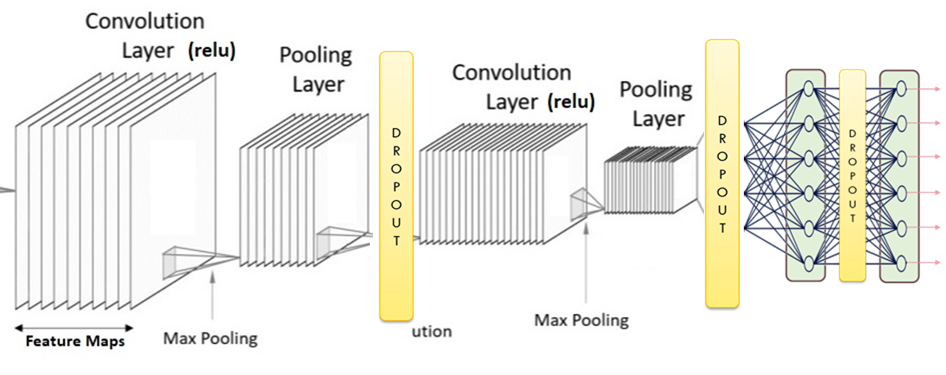

* **Conv Layer**: extraerá diferentes features de las imágenes
* **Pooling Layer**: Reduce las dimensiones de las imágenes tras una capa convolucional
* **Fully Connected Layer**: Tras las capas convolucionales, aplanamos las features y las introducimos como entrada de una red neuronal normal.
* **Output Layer**: Las predicciones de la red

*Con los siguientes hiperparámetros:*  

***Primer juego Conv-Pooling:*** 
* *Conv -> kernel de 3x3, stride = (1,1), padding = "same", activation = "relu", número de filtros = 64*  
* *Pooling -> max, kernel 2x2 (el stride por defecto es igual al kernel, 2x2) -> Vamos a reducir en 2x2, 4 el número de features*  
* *Features de salida: 16x16x64 = 16384*

*Capa Dropout: 0.25 de ratio*

***Segundo juego Conv-Pooling:*** *Aplicamos expansión, aumentando el número de filtros: queremos buscar más características de las características*  
* *Conv -> kernel de 3x3, stride = (1,1), padding = "same", activation = "relu", número de filtros = 128*  
* *Pooling -> max, kernel 2x2 -> Vamos a reducir en 2x2, 4 el número de features*  
* *Features de salida: 8x8x128 = 8192*
  
*Capa Dropout: 0.25 de ratio*  

*Capa aplanadora: Flatten() -> Nos deja cada instancia en un vector de 8192 features*  

***Cabeza clasificación:*** *1 densa oculta y la de salida. En la oculta hacemos una reducción de 8192 a 512, un factor de 16. Podríamos haberla dejado en 32x32x3 = 3072 features, que es el número que meteríamos en un modelo tradicional*
* *Capa Oculta Densa: 512 unidades, activación "relu", seguida de un Dropout de 0.5*
* *Capa densa de salida: 1 unidad (es clasificador binario), activación "sigmoid" (la probabilidad de ser la clase 1)*


In [33]:
layers = [
    keras.layers.Input(shape=(32,32,3)),
    keras.layers.Conv2D(64, (3,3), activation = 'relu', padding= "same"), # Padding "valid" (sin relleno, la salida encoge) o "same" (rellena para mantener la resolución)
    keras.layers.MaxPooling2D(pool_size = (2,2), padding = "same"), # 2x2 -> A dividir por 2 la resolución de cada dimensión de la capa anterior, 32x32 -> 16x16 
    keras.layers.Dropout(rate = 0.25),

    keras.layers.Conv2D(128, (3,3), activation = 'relu', padding= "same"),
    keras.layers.MaxPooling2D(pool_size = (2,2), padding = "same"), # 16x16 -> 8x8
    keras.layers.Dropout(rate = 0.25),
    
    keras.layers.Flatten(),
    keras.layers.Dense(512, activation='relu'), # 8192 -> 512
    keras.layers.Dropout(rate = 0.5),
    #keras.layers.Dense(2, activation='softmax') # -> loss = "sparse_categorical_crossentropy" (categorical_crossentropy es cuando y_train es one-hot: [0,1] o [0,0,1,0,0])
    keras.layers.Dense(1, activation='sigmoid') # -> loss = "binary_crossentropy"
]

model = keras.Sequential(layers)

#### Otros hiperparámetros

*Veamos el tamaño de entrada de datos:*

In [34]:
X_train.size

12288000

*Nos vale un Adam, podríamos probar un SGD*

In [35]:
optimizer = keras.optimizers.Adam()

In [36]:
metrics = ["accuracy"] # dataset equilibrado
loss = "binary_crossentropy" # Es un clasificador binario

*Tenemos 4000 instancias, no son tantas así que emplearemos un batch size de 32*

In [37]:
batch_size = 32

len(X_train)*0.8/batch_size

100.0

*Cada época tendrá 100 pasadas por el algoritmo de entrenamiento (actualizaciones de pesos), también llamadas steps. Incluso podríamos aumentar el batch_size a 48-64*

*Escogemos un número alto de épocas y usamos un EarlyStopping con paciencia 10 para no tener que depender del número de épocas (y con `restore_best_weights` para quedarnos con el mejor modelo y no con el de la última época)*

In [38]:
num_epochs = 100

In [39]:
earlyS = keras.callbacks.EarlyStopping(patience = 10, restore_best_weights = True) # Al parar recuperamos los pesos de la mejor época

*Compilamos y mostramos un resumen del modelo*

In [40]:
model.compile(optimizer= optimizer,
              loss= loss,
              metrics= metrics)

In [41]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     4,194,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,270,977 (16.29 MB)

 Trainable params: 4,270,977 (16.29 MB)

 Non-trainable params: 0 (0.00 B)

### #3

*Hora de entrenar y mostrar ese entrenamiento, pero primero vamos a lanzar una sola época para ver tiempos y antes convertir el target a numérico*

In [42]:
y_train[np.array([1,2,3560])]

array(['cat', 'cat', 'dog'], dtype='<U3')

In [43]:
y_train_num = np.array([0 if y == "cat" else 1 for y in y_train]) # Tiene que ser un array de numpy o no lo admitirá el fit si queremos validation set

*Como vamos a tener que lanzar varios entrenamientos para poder simular un reseteo de pesos creamos una función que nos hace eso, nos devuelve el modelo preparado para un nuevo fit*

In [44]:
def prepare_model(resolucion = (32,32)):
    layers = [
    keras.layers.Input(shape=(32,32,3)),
    keras.layers.Conv2D(64,(3,3), activation = 'relu', padding= "same"),
    keras.layers.MaxPooling2D(pool_size = (2,2), padding = "same"),
    keras.layers.Dropout(rate = 0.25),
    
    keras.layers.Conv2D(128,(3,3), activation = 'relu', padding= "same"),
    keras.layers.MaxPooling2D(pool_size = (2,2), padding = "same"),
    keras.layers.Dropout(rate = 0.25),
    
    keras.layers.Flatten(),
    keras.layers.Dense(512, activation='relu'),
    keras.layers.Dropout(rate = 0.5),
    keras.layers.Dense(1, activation='sigmoid')
    ]
    
    model = keras.Sequential(layers)
    optimizer = keras.optimizers.Adam()
    metrics = ["accuracy"] # dataset equilibrado
    loss = "binary_crossentropy" # Es un clasificador binario
    
    model.compile(optimizer= optimizer,
              loss= loss,
              metrics= metrics)
    
    return model
    

*Podemos probar un entrenamiento con una única época y extrapolar la duración de nuestro hipotético entrenamiento posterior con 100 épocas, pero ojo que **esto no debe hacerse si el entrenamiento se realiza con GPU** porque en ese caso la primera época siempre es mucho más lenta que el resto.*

In [45]:
model = prepare_model()

t_zero = time()

history = model.fit(X_train,
          y_train_num,
          epochs=1,
          batch_size= batch_size,
          callbacks = [earlyS],
          validation_split=0.2)

dur_epoca = time()-t_zero

100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.5898 - loss: 0.7342 - val_accuracy: 0.0000e+00 - val_loss: 0.8187


In [46]:
print(dur_epoca)

3.8286960124969482


*Unos 5 segundos por época: podemos usar un número alto de épocas (el EarlyStopping parará antes). Eso sí, ojo con los resultados: si son excesivamente positivos, tendríamos que estar preocupados.*  

*Entrenamos ahora con los datos ORDENADOS (sin shuffle) y guardamos los datos de entrenamiento en la variable history.*

*Ojo a un detalle importante: `validation_split` **no baraja**, coge siempre el **último 20%** de los datos que le pasamos. Como nuestros datos están ordenados (2000 gatos y luego 2000 perros), el conjunto de validación serán 800 perros y la red entrenará con 2000 gatos y sólo 1200 perros. Fíjate en lo que pasa con `val_accuracy` en las primeras épocas.*

In [47]:
model = prepare_model()

t_zero = time()

history = model.fit(X_train,
          y_train_num,
          epochs= num_epochs,
          batch_size= batch_size,
          callbacks = [earlyS],
          validation_split=0.2)

dur_epoca = time()-t_zero

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.6031 - loss: 0.6818 - val_accuracy: 0.0000e+00 - val_loss: 0.7684
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.6337 - loss: 0.6417 - val_accuracy: 0.6725 - val_loss: 0.6619
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.6609 - loss: 0.6141 - val_accuracy: 0.6263 - val_loss: 0.6786
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.7098 - loss: 0.5799 - val_accuracy: 0.6250 - val_loss: 0.6775
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - accuracy: 0.7090 - loss: 0.5615 - val_accuracy: 0.6950 - val_loss: 0.6001
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.7381 - loss: 0.5283 - val_accuracy: 0.6825 - val_loss: 0.6023
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.7603 - loss: 0.5101 - val_accuracy: 0.7788 - val_loss: 0.5138
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.7688 - loss: 0.475

*Fíjate en que no vamos a evaluar este modelo contra test: el test lo reservamos para el modelo final. Además, su validación (todo perros) no nos sirve para compararlo con nada. Aprovechamos para preparar ya el target numérico de test.*

In [48]:
y_test_num = np.array([0 if y == "cat" else 1 for y in y_test])

*Como ves, el orden de los datos de entrada (primero 2000 gatos y luego 2000 perros) estropea la validación. Vamos a barajarlos y volvemos a entrenar.*

In [49]:
indices = shuffle(np.arange(len(X_train)), random_state = 42) # Guardamos la permutación para reutilizar la misma validación más adelante
X_s, y_s = X_train[indices], y_train_num[indices]

In [50]:
model = prepare_model()

t_zero = time()

history_shuffle = model.fit(X_s,
          y_s,
          epochs= num_epochs,
          batch_size= batch_size,
          callbacks = [earlyS],
          validation_split=0.2)

dur_epoca = time()-t_zero

Epoch 1/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.5272 - loss: 0.7287 - val_accuracy: 0.6187 - val_loss: 0.6692
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.6270 - loss: 0.6613 - val_accuracy: 0.6513 - val_loss: 0.6226
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.6682 - loss: 0.6157 - val_accuracy: 0.7225 - val_loss: 0.5766
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.6907 - loss: 0.5934 - val_accuracy: 0.7075 - val_loss: 0.5781
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.7127 - loss: 0.5705 - val_accuracy: 0.7275 - val_loss: 0.5618
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - accuracy: 0.7290 - loss: 0.5480 - val_accuracy: 0.7250 - val_loss: 0.5478
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - accuracy: 0.7624 - loss: 0.5015 - val_accuracy: 0.7412 - val_loss: 0.5423
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - accuracy: 0.7773 - loss: 0.4753 - 

*Este es el modelo de nuestra solución principal (pasos 3 a 5), así que ahora sí lo evaluamos contra test:*

In [51]:
results = model.evaluate(X_test, y_test_num)
print("test loss, test acc:", results)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7886 - loss: 0.4753
test loss, test acc: [0.5509164333343506, 0.7210000157356262]


> *Nota: Los valores que se imprimen en pantalla durante la evaluación son medias móviles calculadas a lo largo del proceso de inferencia. La variable *results* contiene la pérdida (loss) y el acierto (accuracy) medio final, calculados a través de todos los *batches* o lotes del conjunto de datos de prueba. **Son estos resultados finales los que debemos usar para evaluar el rendimiento de nuestro modelo contra el conjunto de datos de prueba.***

*Comparemos la evolución de los dos entrenamientos, con los datos ordenados y barajados:*

In [52]:
df_evol = pd.DataFrame(history.history)
df_evol_shuffle = pd.DataFrame(history_shuffle.history)

<Axes: >

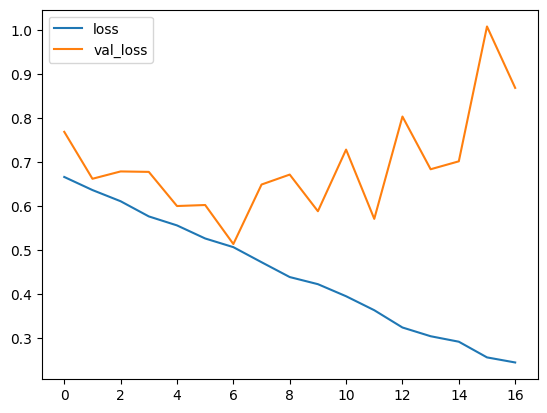

In [53]:
df_evol[["loss","val_loss"]].plot()

<Axes: >

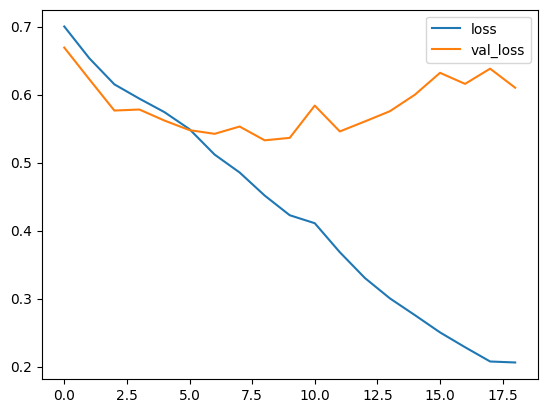

In [54]:
df_evol_shuffle[["loss","val_loss"]].plot()

*Con los datos ordenados la validación (que son todo perros) empieza con una accuracy cercana a 0 y su pérdida oscila muchísimo de una época a otra: el modelo ha visto muchos más gatos que perros y la validación no es representativa. Con los datos barajados la curva de validación es mucho más estable y nos permite decidir de verdad cuándo parar. En ambos casos train y validación se separan pronto (overfitting): no siempre debemos parar en cuanto se separan, pero tampoco esperar mucho más.*

### #4

In [55]:
predictions = model.predict(X_test)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


*Nuestra neurona de salida con activación sigmoide nos devuelve las probabilidades de 0 a 1, de modo que:*
- *Probabilidad menor o igual a 0.5 -> Predice clase 0 (gatete)*  
- *Probabilidad mayor que 0.5 -> Predice clase 1 (perrete)*  

*Por tanto, para poder imprimir el reporte de clasificación o la matriz de confusión debemos recuperar nuestras etiquetas originales con, por ejemplo, una comprensión de lista.*

In [56]:
y_pred = ["dog" if prediction[0] > 0.5 else "cat" for prediction in model.predict(X_test)]
print(classification_report(y_test, y_pred))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
              precision    recall  f1-score   support

         cat       0.69      0.80      0.74       500
         dog       0.76      0.64      0.70       500

    accuracy                           0.72      1000
   macro avg       0.73      0.72      0.72      1000
weighted avg       0.73      0.72      0.72      1000



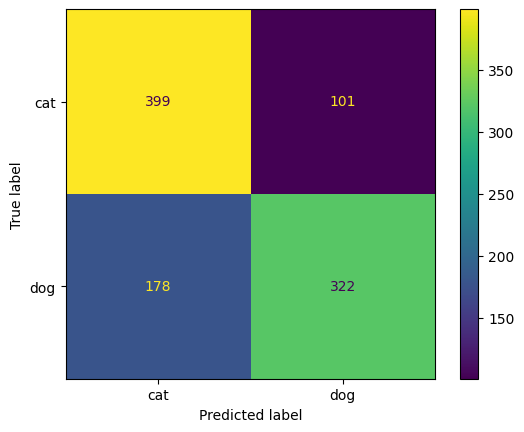

In [57]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

*Capta más gatos (mayor recall) pero al precio de ser menos preciso con ellos: dice que hay más gatos de los que hay. Con los perros es más preciso y, por eso mismo, los capta en menor número.*

### #5

*Para seleccionar aquellas imágenes que el modelo confunde con mayor confianza construiremos un dataframe con el fichero, la clase real, la predicción y la confianza de esa predicción:*

*Recuerda, si la probabilidad es menor o igual a 0.5 el modelo pensará que es un gato, y lo pensará con mayor confianza cuanto menor sea la probabilidad -> por tanto, podremos hacer la operación "1 menos probabilidad de la neurona" para conocer esa confianza.*  

*Así mismo, si la probabilidad es mayor que 0.5 el modelo pensará que es un perro, y lo pensará con mayor confianza cuanto mayor sea la probabilidad -> por tanto, no es necesario hacer ninguna operación, ya tenemos la confianza.*

In [58]:
confianza = [ (1-prediction[0]) if prediction[0] <= 0.5 else prediction[0] for prediction in model.predict(X_test)]
df_pred = pd.DataFrame({"ficheros": test_map,"True": y_test,"Prediction": y_pred, "Confianza": confianza})
df_pred

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


,ficheros,True,Prediction,Confianza
0,test/cats/cat.12117.jpg,cat,cat,0.818394
1,test/cats/cat.10483.jpg,cat,cat,0.767690
2,test/cats/cat.3810.jpg,cat,dog,0.502957
3,test/cats/cat.3294.jpg,cat,cat,0.828366
4,test/cats/cat.2915.jpg,cat,cat,0.828529
...,...,...,...,...
995,test/dogs/dog.169.jpg,dog,dog,0.653339
996,test/dogs/dog.5893.jpg,dog,dog,0.910324
997,test/dogs/dog.105.jpg,dog,dog,0.760703
998,test/dogs/dog.141.jpg,dog,cat,0.918993


In [59]:
errores = df_pred["True"] != df_pred["Prediction"]
son_gatos = df_pred["True"] == "cat"
son_perros = df_pred["True"] == "dog"
gatos_dificiles = df_pred[son_gatos & errores]["Confianza"].nlargest(int(len(df_pred[son_gatos & errores])*0.1)).index.to_list()
perros_dificiles = df_pred[son_perros & errores]["Confianza"].nlargest(int(len(df_pred[son_perros & errores])*0.1)).index.to_list()


In [60]:
df_pred.loc[gatos_dificiles]

,ficheros,True,Prediction,Confianza
335,test/cats/cat.3847.jpg,cat,dog,0.926006
454,test/cats/cat.6157.jpg,cat,dog,0.918031
421,test/cats/cat.12378.jpg,cat,dog,0.906704
134,test/cats/cat.3620.jpg,cat,dog,0.906452
308,test/cats/cat.328.jpg,cat,dog,0.889475
402,test/cats/cat.10689.jpg,cat,dog,0.880116
346,test/cats/cat.9428.jpg,cat,dog,0.866597
183,test/cats/cat.11127.jpg,cat,dog,0.866514
297,test/cats/cat.11323.jpg,cat,dog,0.864060
370,test/cats/cat.4869.jpg,cat,dog,0.852792


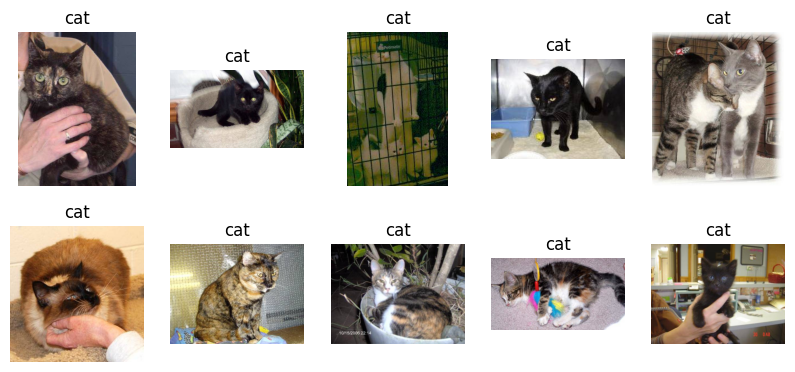

In [61]:
show_images_files(df_pred.loc[gatos_dificiles]["ficheros"], df_pred.loc[gatos_dificiles]["True"].values)

In [62]:
df_pred.loc[perros_dificiles]

,ficheros,True,Prediction,Confianza
877,test/dogs/dog.7602.jpg,dog,cat,0.992394
726,test/dogs/dog.843.jpg,dog,cat,0.985378
720,test/dogs/dog.8597.jpg,dog,cat,0.965743
822,test/dogs/dog.10754.jpg,dog,cat,0.956840
988,test/dogs/dog.2784.jpg,dog,cat,0.941400
715,test/dogs/dog.2960.jpg,dog,cat,0.939494
901,test/dogs/dog.5622.jpg,dog,cat,0.919227
998,test/dogs/dog.141.jpg,dog,cat,0.918993
878,test/dogs/dog.9995.jpg,dog,cat,0.905971
829,test/dogs/dog.1040.jpg,dog,cat,0.896931


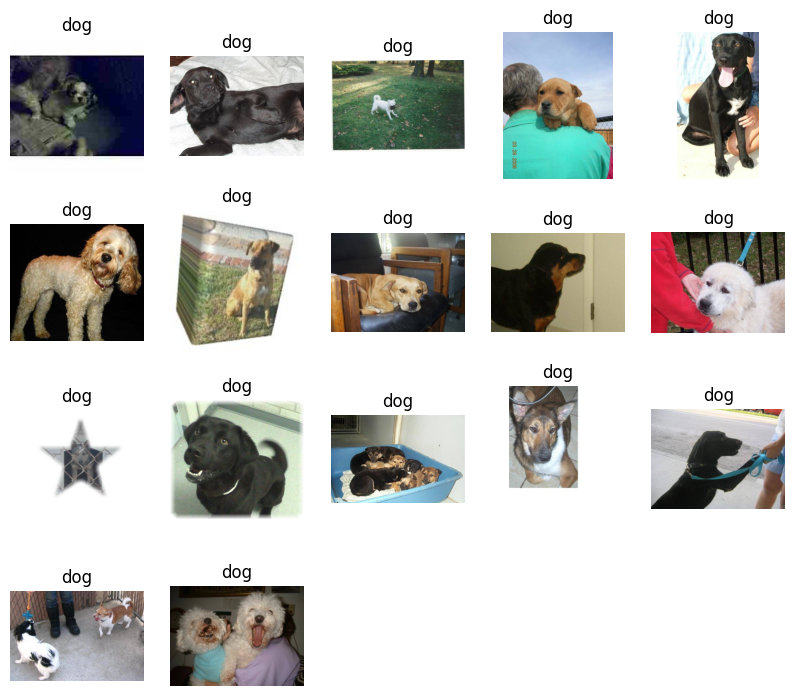

In [63]:
show_images_files(df_pred.loc[perros_dificiles]["ficheros"], df_pred.loc[perros_dificiles]["True"].values)

*Cabe discutir si la resolución afecta: sí, nuestro modelo ve las imágenes a 32x32, así que la selección sólo es válida si el CAPTCHA (o el sistema atacante) trabaja con una resolución parecida. Por otro lado, que sean imágenes que a un humano no le costarían pero a un modelo sí las hace idóneas para el trabajo, porque fallarlas es un indicio claro de que quien responde es un modelo*

### EXTRA

*Para terminar vamos a ver una de las técnicas que se pueden emplear para tener más información en un clasificador de imágenes (y que podría servir, hasta cierto punto, como técnica de generación sintética u oversampling para equilibrar datasets)*

*Vamos a ver cómo usar el aumentado de datos (data augmentation) de Keras para imágenes*

#### Image data generator

*Primero vamos a construir un dataframe con la estructura filename-category (ruta de la imagen, relativa a `PATH_DATA`, y su clase) a partir de las imágenes de train que ya hemos muestreado. Nos servirá después para ver otra capacidad de keras*

In [64]:
train_augmented = pd.DataFrame({"filename": train_map, "category": y_train})
train_augmented.head(10)

,filename,category
0,train/cats/cat.12031.jpg,cat
1,train/cats/cat.10452.jpg,cat
2,train/cats/cat.3822.jpg,cat
3,train/cats/cat.3252.jpg,cat
4,train/cats/cat.2848.jpg,cat
5,train/cats/cat.1303.jpg,cat
6,train/cats/cat.11868.jpg,cat
7,train/cats/cat.8813.jpg,cat
8,train/cats/cat.11594.jpg,cat
9,train/cats/cat.9638.jpg,cat


*El objeto ImageDataGenerator va a servirnos para generar una imagen modificada de una imagen original, mediante rotaciones, reescalados, desplazamientos, zooms, flips, etc.*

*NOTA: `ImageDataGenerator` es una clase heredada (legacy): en Keras 3 ya no está en `keras.preprocessing` y sólo se puede importar desde `tensorflow.keras`, aunque sigue funcionando. La alternativa moderna son las capas de aumentado (`keras.layers.RandomFlip`, `RandomRotation`, `RandomZoom`...) que se colocan al principio del modelo. Lo usamos aquí porque es muy ilustrativo y lo encontrarás en muchísimo código.*

In [65]:
'''
NO genera X imágenes sintéticas de antemano. Simplemente en cada época, en vez de coger
cada imagen del dataset tal cual, coge una versión transformada al azar (algo diferente).
Así la red ve más "perspectivas" de cada imagen.
Las imágenes las va generando según entrena
https://www.analyticsvidhya.com/blog/2020/08/image-augmentation-on-the-fly-using-keras-imagedatagenerator/

'''

example_df = train_augmented.sample(n=1).reset_index(drop=True)

train_datagen = ImageDataGenerator(
    rotation_range=15, # Ángulo de rotación (en grados)
    rescale=1./255, # Escalado, ya nos escala las imágenes
    shear_range=0.1, # Inclina las imágenes: no es un giro, es una inclinación, como hacerlas "cursivas"
    zoom_range=0.2, # Zoom
    horizontal_flip=True, # Volteo horizontal (efecto espejo)
    width_shift_range=0.1, # Desplazamiento horizontal de los píxeles
    height_shift_range=0.1 # Desplazamiento vertical de los píxeles
)


*Hay dos formas de utilizarlo: a partir de los ficheros y a partir de los datos ya cargados*

In [66]:
example_df

,filename,category
0,train/cats/cat.6933.jpg,cat


In [67]:

example_generator = train_datagen.flow_from_dataframe(
    example_df, 
    directory=PATH_DATA, # Las rutas del dataframe son relativas a este directorio
    x_col='filename',
    y_col='category',
    target_size=(32, 32),
)

Found 1 validated image filenames belonging to 1 classes.


*Generamos ahora 15 imágenes sintéticas, a las que se aplican los cambios aleatoriamente*

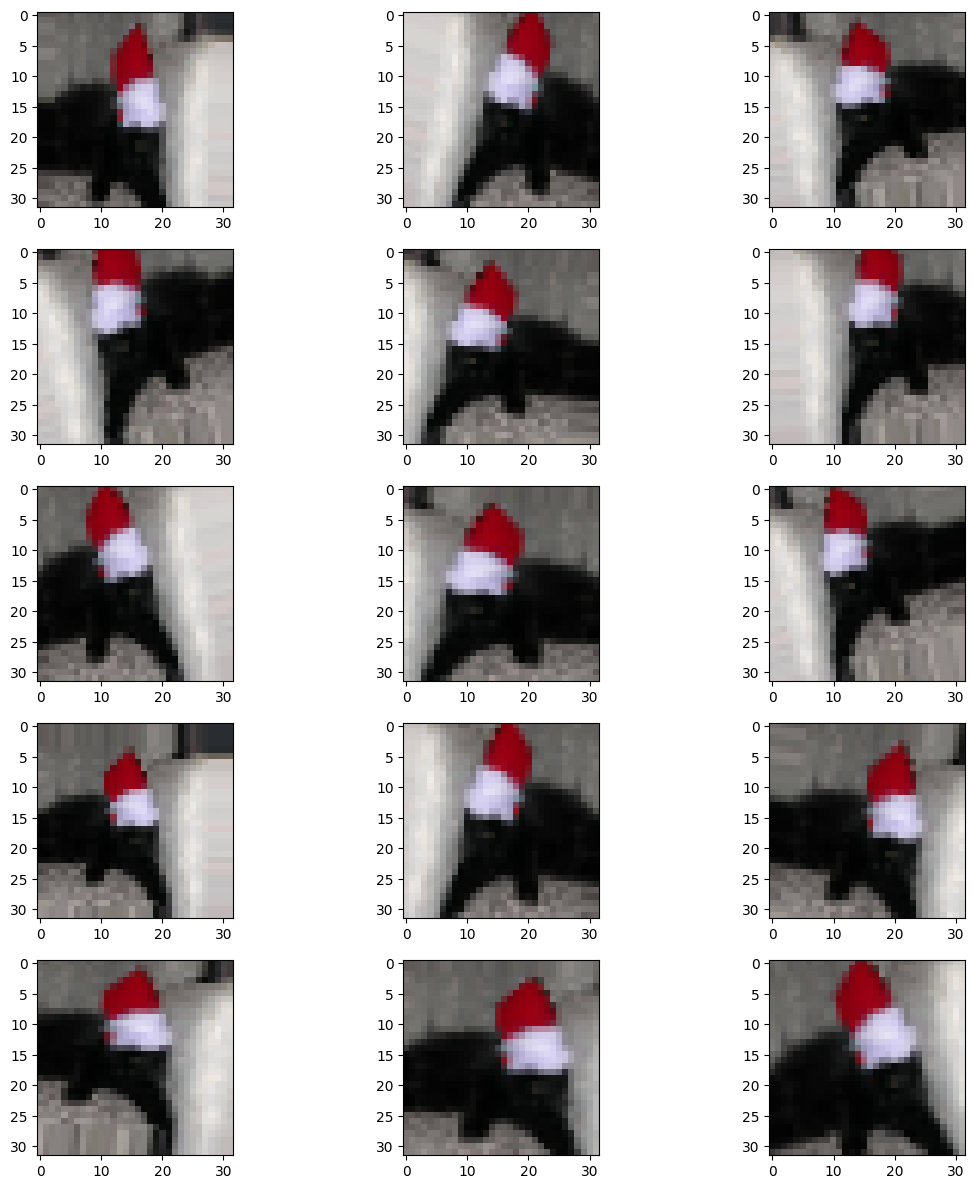

In [68]:
plt.figure(figsize=(12, 12))

for i in range(0, 15):
    plt.subplot(5, 3, i+1)
    for X_batch, Y_batch in example_generator:
        image = X_batch[0]
        plt.imshow(image)
        break
    
plt.tight_layout()
plt.show()

In [69]:

example_generator = train_datagen.flow(
    X_train[0:3]*255,
    y_train[0:3]
)

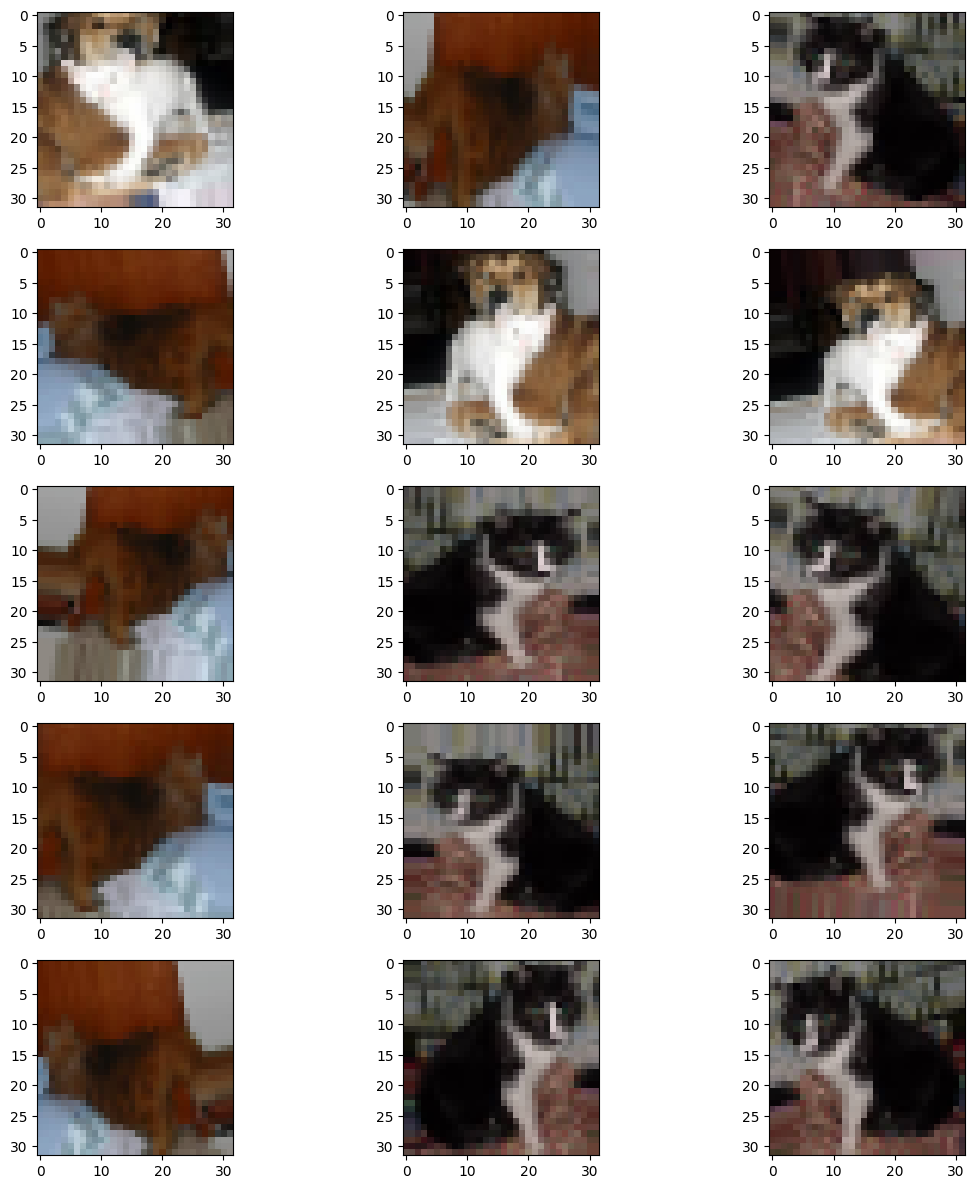

In [70]:
plt.figure(figsize=(12, 12))

for i in range(0, 15):
    plt.subplot(5, 3, i+1)
    for X_batch, Y_batch in example_generator:
        image = X_batch[0]
        plt.imshow(image)
        break
plt.tight_layout()
plt.show()

#### Aplicado a un modelo y un entrenamiento

*Tenemos que generar el dataset de validación aparte, porque ese no va a llevar aumentado. Para poder comparar con el modelo anterior usamos exactamente la misma validación: las 800 últimas imágenes de la permutación `indices` que usamos al barajar*

In [71]:
train_df = train_augmented.iloc[indices[:-800]]
validate_df = train_augmented.iloc[indices[-800:]] # Las mismas 800 imágenes que usó validation_split en el modelo anterior

In [72]:
train_df = train_df.reset_index(drop=True)
validate_df = validate_df.reset_index(drop=True)

In [73]:
train_df

,filename,category
0,train/cats/cat.2681.jpg,cat
1,train/dogs/dog.5607.jpg,dog
2,train/cats/cat.8051.jpg,cat
3,train/dogs/dog.2066.jpg,dog
4,train/dogs/dog.1552.jpg,dog
...,...,...
3195,train/dogs/dog.2459.jpg,dog
3196,train/dogs/dog.9748.jpg,dog
3197,train/cats/cat.5806.jpg,cat
3198,train/dogs/dog.526.jpg,dog


In [74]:
total_train = train_df.shape[0]
total_validate = validate_df.shape[0]

print("Shape train", total_train)
print("Shape validation", total_validate)
validate_df.head()

Shape train 3200
Shape validation 800


,filename,category
0,train/dogs/dog.4666.jpg,dog
1,train/cats/cat.5143.jpg,cat
2,train/cats/cat.3632.jpg,cat
3,train/dogs/dog.3580.jpg,dog
4,train/cats/cat.11767.jpg,cat


#### Generador de entrenamiento

In [75]:
train_generator = train_datagen.flow_from_dataframe(
    train_df, 
    directory=PATH_DATA, # Las rutas del dataframe son relativas a este directorio
    x_col='filename',
    y_col='category',
    target_size=(32, 32),
    class_mode='binary', # Porque es binaria; si fuera multiclase con la clase en un solo valor -> "sparse" (otras configuraciones, ver la documentación)
    batch_size= batch_size
)

Found 3200 validated image filenames belonging to 2 classes.


#### Generador de validación

In [76]:
validation_datagen = ImageDataGenerator(rescale=1./255) # Solo vamos a reescalar

validation_generator = validation_datagen.flow_from_dataframe(
    validate_df, 
    directory=PATH_DATA, # Las rutas del dataframe son relativas a este directorio
    x_col='filename',
    y_col='category',
    target_size=(32, 32),
    class_mode='binary',
    batch_size= batch_size
)

Found 800 validated image filenames belonging to 2 classes.


#### Entrenamiento

In [77]:
model = prepare_model() # Modelo nuevo, con pesos sin entrenar

In [78]:
history = model.fit(
    train_generator, 
    epochs= num_epochs,
    validation_data=validation_generator,
    callbacks= [earlyS]
)

Epoch 1/100


100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - accuracy: 0.4941 - loss: 0.7314 - val_accuracy: 0.5800 - val_loss: 0.6885
Epoch 2/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 80ms/step - accuracy: 0.5303 - loss: 0.6897 - val_accuracy: 0.5975 - val_loss: 0.6700
Epoch 3/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 76ms/step - accuracy: 0.5845 - loss: 0.6739 - val_accuracy: 0.6150 - val_loss: 0.6417
Epoch 4/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step - accuracy: 0.5804 - loss: 0.6741 - val_accuracy: 0.6475 - val_loss: 0.6372
Epoch 5/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 73ms/step - accuracy: 0.5933 - loss: 0.6566 - val_accuracy: 0.6913 - val_loss: 0.6131
Epoch 6/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - accuracy: 0.6384 - loss: 0.6405 - val_accuracy: 0.7063 - val_loss: 0.5856
Epoch 7/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - accuracy: 0.6330 - loss: 0.6441 - val_accuracy: 0.7175 - val_loss: 0.5651
Epoch 8/100
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - accuracy: 0.6443 - loss: 0.6234 - val_accuracy

*Antes de ir a test, comparamos los dos modelos en validación (las mismas 800 imágenes) quedándonos, en cada uno, con la mejor época, que es la que restaura el EarlyStopping:*

In [79]:
def mejor_epoca(history):
    df = pd.DataFrame(history.history)
    return df.loc[df["val_loss"].idxmin(), ["val_loss", "val_accuracy"]]

pd.DataFrame({"Sin aumentado": mejor_epoca(history_shuffle), "Con aumentado": mejor_epoca(history)})

,Sin aumentado,Con aumentado
val_loss,0.532775,0.443397
val_accuracy,0.733750,0.806250


*Y ahora sí, evaluamos el modelo con aumentado contra test:*

In [80]:
results = model.evaluate(X_test, y_test_num)
print("test loss, test acc:", results)

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7628 - loss: 0.5013
test loss, test acc: [0.46482762694358826, 0.7760000228881836]


*Con el aumentado de imágenes el entrenamiento es más lento (cada época hay que leer y transformar las imágenes), pero el modelo sobreajusta mucho menos (fíjate en que ahora train y validación van de la mano) y es mejor en validación, lo que se confirma en test.*

*Ahora probemos a hacer una predicción de una imagen que no está en ninguno de nuestros sets.*

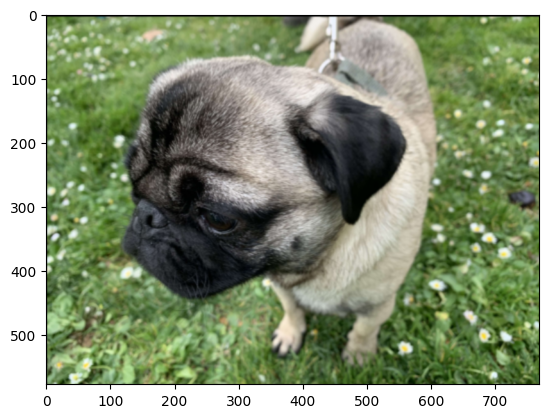

In [81]:
RUTA_GINI = "../data/gini_test.png"
if not os.path.exists(RUTA_GINI): # Por ejemplo en Colab, la descargamos del repo del curso
    RUTA_GINI = keras.utils.get_file("gini_test.png", "https://raw.githubusercontent.com/DS-TB-FundacionUniversia/2026-09-DS-Universia/main/05_Deep_Learning/02_Convolucionales_CNN/data/gini_test.png")
image = imread(RUTA_GINI)
plt.imshow(image);

In [82]:
image.shape

(577, 770, 4)

In [83]:
# Ajustamos tamaño y normalizamos
image = np.array([cv2.resize(image, (32, 32))/255])

In [84]:
image.shape

(1, 32, 32, 4)

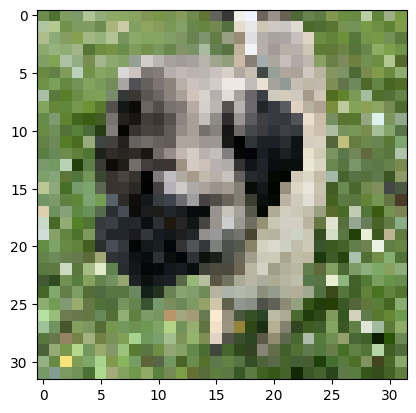

In [85]:
plt.imshow(image[0])
plt.show()

In [86]:
predictions = model.predict(image).round(3)
print("predictions shape:", predictions.shape)

ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 of layer "conv2d_8" is incompatible with the layer: expected axis -1 of input shape to have value 3, but received input with shape (1, 32, 32, 4)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(1, 32, 32, 4), dtype=float32)
  • training=False
  • mask=None

*¿Por qué nos da error la inferencia?*   

*Fíjate bien en las dimensiones del tensor: en lugar de 3 canales tenemos **¡4 canales!***   

*Esto ocurre porque la imagen es un PNG y no un JPG, son formatos diferentes, y una de sus diferencias es que los PNG pueden contener un 4º canal llamado "canal alfa" (alpha), que es el que permite crear transparencias usando una máscara.*  

*En esta imagen no hay transparencias, pero eso no significa que no haya canal alfa: simplemente es totalmente opaco. Vamos a comprobarlo haciendo un *imshow* de una vista (usando un slicing).*

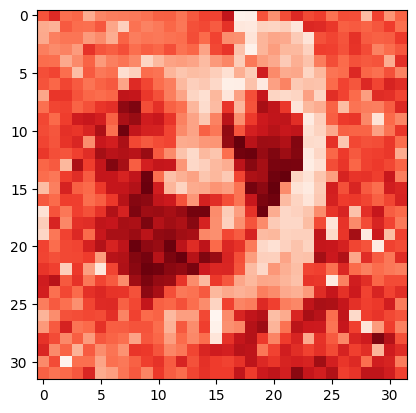

In [87]:
# Canal R
plt.imshow(image[0,:,:,0], cmap="Reds_r")
plt.show()

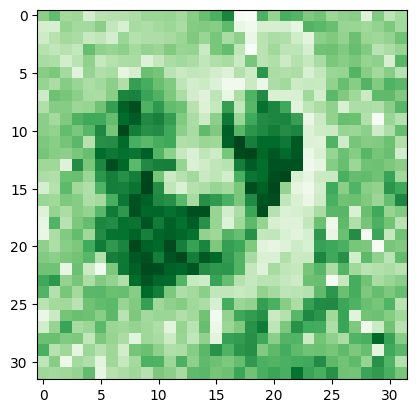

In [88]:
# Canal G
plt.imshow(image[0,:,:,1], cmap="Greens_r")
plt.show()

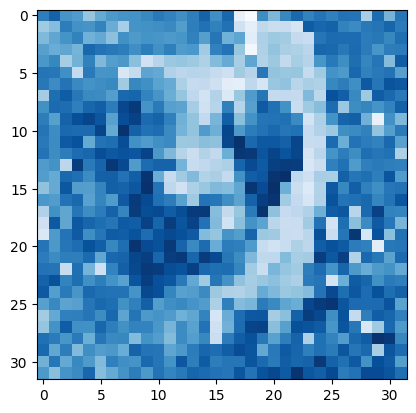

In [89]:
# Canal B
plt.imshow(image[0,:,:,2], cmap="Blues_r")
plt.show()

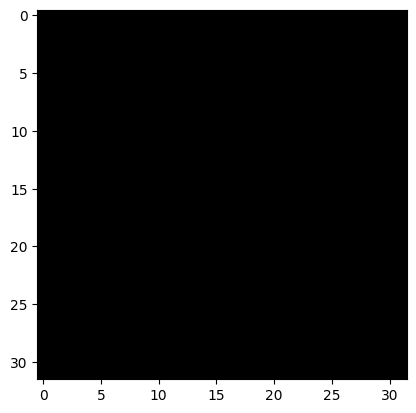

In [90]:
# Canal alfa
plt.imshow(image[0,:,:,3], cmap="Greys_r")
plt.show()

*Y ahí está, tendremos que quitar ese 4º canal para que la imagen pueda ser usada por nuestro modelo.*

In [91]:
image[:,:,:,:-1].shape

(1, 32, 32, 3)

In [92]:
predictions = model.predict(image[:,:,:,:-1]).round(3)
print("predictions shape:", predictions.shape)
predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
predictions shape: (1, 1)


array([[1.]], dtype=float32)

*Recuerda: la salida es la probabilidad de la clase 1 (perro). Gini es un perrete y el modelo así lo cree.*